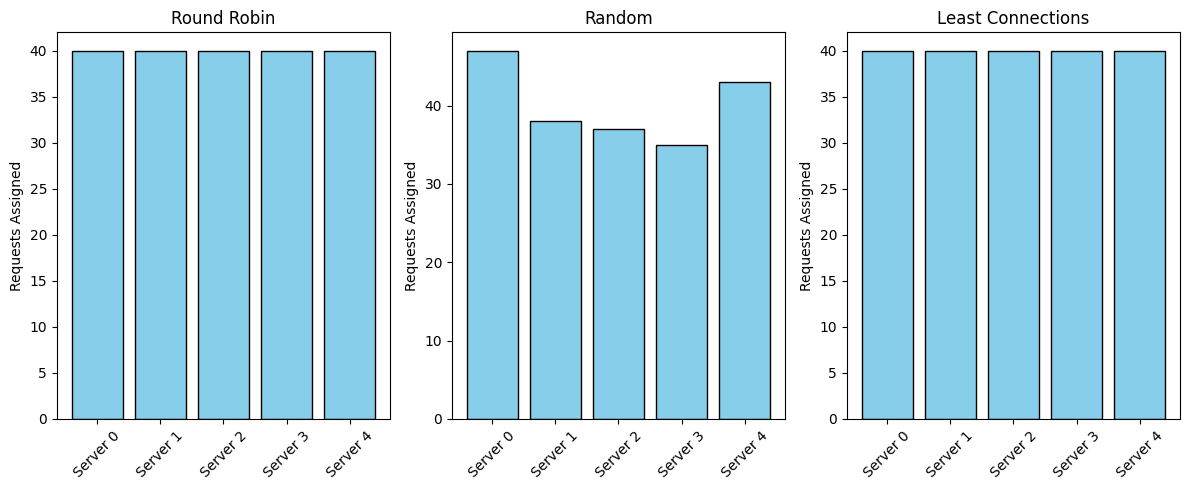

In [ ]:
import random
import matplotlib.pyplot as plt

# -------------------------------
# Service (Server) Class
# -------------------------------
class ServiceInstance:
    def __init__(self, id):
        self.id = id
        self.current_load = 0

    def handle_request(self):
        self.current_load += 1


class LoadBalancer:
    def __init__(self, servers, strategy="round_robin"):
        self.servers = servers
        self.strategy = strategy
        self.counter = 0

    def assign_request(self):
        if self.strategy == "round_robin":
            server = self.servers[self.counter % len(self.servers)]
            self.counter += 1

        elif self.strategy == "random":
            server = random.choice(self.servers)

        elif self.strategy == "least_connections":
            server = min(self.servers, key=lambda s: s.current_load)

        server.handle_request()
        return server


class Simulator:
    def __init__(self, num_servers, num_requests, strategy):
        self.servers = [ServiceInstance(i) for i in range(num_servers)]
        self.lb = LoadBalancer(self.servers, strategy)
        self.num_requests = num_requests

    def run(self):
        for _ in range(self.num_requests):
            self.lb.assign_request()

    def results(self):
        return {f"Server {s.id}": s.current_load for s in self.servers}


def run_and_plot(num_servers=5, num_requests=100, strategies=None):
    if strategies is None:
        strategies = ["round_robin", "random", "least_connections"]

    plt.figure(figsize=(12, 5))

    for i, strategy in enumerate(strategies, 1):
        sim = Simulator(num_servers, num_requests, strategy)
        sim.run()
        results = sim.results()

        plt.subplot(1, len(strategies), i)
        plt.bar(results.keys(), results.values(), color="skyblue", edgecolor="black")
        plt.title(f"{strategy.replace('_', ' ').title()}")
        plt.xticks(rotation=45)
        plt.ylabel("Requests Assigned")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    run_and_plot(num_servers=5, num_requests=200)